In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    cross_val_predict,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.pipeline import Pipeline

print("Task 3.1 Libraries Imported Successfully!")

Task 3.1 Libraries Imported Successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving appointments_clean.csv to appointments_clean.csv


In [3]:
df = pd.read_csv("appointments_clean.csv")

print("Dataset Loaded Successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (990, 16)


,appointment_id,patient_id,clinic_id,booked_on,appt_date,age,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status,lead_days,no_show
0,A0001,P509,C05,2025-01-24,2025-01-25,60,F,18.0,850,Phone,Consultation,Yes,1,No-Show,1,1
1,A0002,P046,C07,2025-05-27,2025-06-06,39,M,12.5,350,Walk-In,Follow-up,No,2,Attended,10,0
2,A0003,P009,C02,2025-03-24,2025-03-30,63,F,4.1,850,Walk-In,Consultation,No,0,Attended,6,0
3,A0004,P482,C01,2025-04-18,2025-04-22,52,F,7.5,750,App,Consultation,Yes,0,Attended,4,0
4,A0005,P251,C01,2024-11-23,2025-01-02,64,F,19.0,700,Phone,Consultation,No,0,No-Show,40,1


**Task 3.1: Feature Selection**

In [4]:
# Keep appointment IDs separately
appointment_ids = df["appointment_id"].copy()

# Convert reminder_sent Yes/No into 1/0
df["reminder_sent"] = df["reminder_sent"].map({
    "Yes": 1,
    "No": 0
})

# Select required features
X = df[
    [
        "age",
        "distance_km",
        "fee_inr",
        "lead_days",
        "prior_no_shows",
        "reminder_sent",
        "booking_channel",
        "visit_type"
    ]
].copy()

# One-Hot Encoding
X = pd.get_dummies(
    X,
    columns=["booking_channel", "visit_type"],
    dtype=int
)

# Target Variable
y = df["no_show"]

print("Features Created Successfully!")
print("X Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Features Created Successfully!
X Shape: (990, 11)
Target Shape: (990,)


,age,distance_km,fee_inr,lead_days,prior_no_shows,reminder_sent,booking_channel_App,booking_channel_Phone,booking_channel_Walk-In,visit_type_Consultation,visit_type_Follow-up
0,60,18.0,850,1,1,1,0,1,0,1,0
1,39,12.5,350,10,2,0,0,0,1,0,1
2,63,4.1,850,6,0,0,0,0,1,1,0
3,52,7.5,750,4,0,1,1,0,0,1,0
4,64,19.0,700,40,0,0,0,1,0,1,0


In [5]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-Test Split Completed Successfully!")

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

Train-Test Split Completed Successfully!
X_train Shape: (792, 11)
X_test Shape: (198, 11)
y_train Shape: (792,)
y_test Shape: (198,)


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Create baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train baseline model
baseline_model.fit(X_train, y_train)

# Make predictions
baseline_predictions = baseline_model.predict(X_test)

# Calculate accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Model Results")
print("----------------------")
print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Accuracy (%):", round(baseline_accuracy * 100, 2))

Baseline Model Results
----------------------
Baseline Accuracy: 0.7778
Baseline Accuracy (%): 77.78


In [7]:
print("TASK 3.1 FINAL VERIFICATION")
print("=" * 40)

print("Total Samples:", len(X))
print("Total Features:", X.shape[1])

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nMissing Values in Features:", X.isnull().sum().sum())

print("\nBaseline Accuracy:",
      round(baseline_accuracy, 4))

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nTASK 3.1 COMPLETED SUCCESSFULLY!")

TASK 3.1 FINAL VERIFICATION
Total Samples: 990
Total Features: 11

Training Samples: 792
Testing Samples: 198

Missing Values in Features: 0

Baseline Accuracy: 0.7778

Training Target Distribution:
no_show
0    618
1    174
Name: count, dtype: int64

Testing Target Distribution:
no_show
0    154
1     44
Name: count, dtype: int64

TASK 3.1 COMPLETED SUCCESSFULLY!


**Task 3.2 — Logistic Regression**

In [8]:
# Task 3.2 - Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create Pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic Regression Pipeline Created Successfully!")

Logistic Regression Pipeline Created Successfully!


In [9]:
# Train the model

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [10]:
# Predict on test data

y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions Generated Successfully!")

print("Total Predictions:", len(y_pred_lr))

Predictions Generated Successfully!
Total Predictions: 198


In [11]:
# Evaluate Logistic Regression

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("LOGISTIC REGRESSION RESULTS")
print("=" * 35)

print("Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1 Score:", round(lr_f1, 4))
print("ROC-AUC:", round(lr_roc_auc, 4))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.7929
Precision: 0.5556
Recall: 0.3409
F1 Score: 0.4225
ROC-AUC: 0.7528


Confusion Matrix:
[[142  12]
 [ 29  15]]


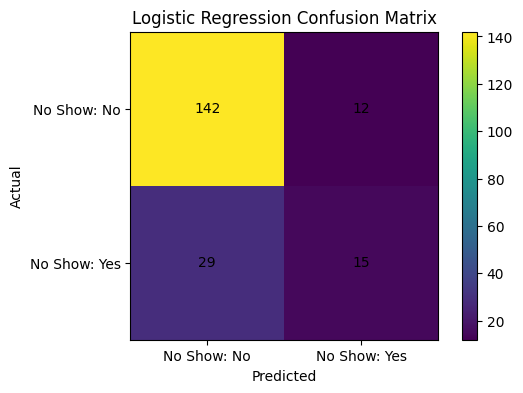

In [12]:
# Confusion Matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

plt.figure(figsize=(6, 4))

plt.imshow(cm_lr)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

plt.xticks([0, 1], ["No Show: No", "No Show: Yes"])
plt.yticks([0, 1], ["No Show: No", "No Show: Yes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_lr[i, j],
                 ha="center", va="center")

plt.show()

**Task 3.3 — Decision Tree**

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

print("Decision Tree Libraries Imported Successfully!")

Decision Tree Libraries Imported Successfully!


In [14]:
# Full Decision Tree Model

tree_full = DecisionTreeClassifier(
    random_state=42
)

tree_full.fit(X_train, y_train)

print("Full Decision Tree Model Trained Successfully!")

Full Decision Tree Model Trained Successfully!


In [15]:
# Training Accuracy
full_train_accuracy = accuracy_score(
    y_train,
    tree_full.predict(X_train)
)

# Testing Accuracy
full_test_accuracy = accuracy_score(
    y_test,
    tree_full.predict(X_test)
)

print("FULL DECISION TREE RESULTS")
print("--------------------------")

print("Training Accuracy:",
      round(full_train_accuracy, 4))

print("Testing Accuracy:",
      round(full_test_accuracy, 4))

FULL DECISION TREE RESULTS
--------------------------
Training Accuracy: 1.0
Testing Accuracy: 0.7374


In [16]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Train Depth 3 Decision Tree
tree_depth3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_depth3.fit(X_train, y_train)

print("Depth 3 Decision Tree Model Trained Successfully!")


Depth 3 Decision Tree Model Trained Successfully!


In [17]:

depth3_train_accuracy = accuracy_score(
    y_train, tree_depth3.predict(X_train)
)

depth3_test_accuracy = accuracy_score(
    y_test, tree_depth3.predict(X_test)
)

print("DEPTH 3 DECISION TREE RESULTS")
print("-----------------------------")
print("Training Accuracy:", round(depth3_train_accuracy, 4))
print("Testing Accuracy:", round(depth3_test_accuracy, 4))


DEPTH 3 DECISION TREE RESULTS
-----------------------------
Training Accuracy: 0.8182
Testing Accuracy: 0.798


In [18]:

comparison_tree = pd.DataFrame({
    "Model": ["Full Decision Tree", "Depth 3 Decision Tree"],
    "Training Accuracy": [
        full_train_accuracy,
        depth3_train_accuracy
    ],
    "Testing Accuracy": [
        full_test_accuracy,
        depth3_test_accuracy
    ]
})

print("DECISION TREE COMPARISON")
display(comparison_tree)

print("\nOverfitting Analysis:")
print(
    "Full Tree has a larger training-testing gap, "
    "indicating overfitting."
)


DECISION TREE COMPARISON


,Model,Training Accuracy,Testing Accuracy
0,Full Decision Tree,1.000000,0.737374
1,Depth 3 Decision Tree,0.818182,0.797980



Overfitting Analysis:
Full Tree has a larger training-testing gap, indicating overfitting.


**Task 3.4 — Random Forest Model**

In [19]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Random Forest Libraries Imported Successfully!")


Random Forest Libraries Imported Successfully!


In [20]:

# Create Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=5,
    class_weight="balanced"
)

# Train Model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [21]:

# Generate Predictions

rf_predictions = rf_model.predict(X_test)

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Predictions Generated Successfully!")
print("Total Predictions:", len(rf_predictions))


Random Forest Predictions Generated Successfully!
Total Predictions: 198


In [22]:

# Random Forest Evaluation Metrics

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions, zero_division=0)
rf_recall = recall_score(y_test, rf_predictions, zero_division=0)
rf_f1 = f1_score(y_test, rf_predictions, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_probabilities)

print("RANDOM FOREST MODEL RESULTS")
print("=" * 35)

print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))


RANDOM FOREST MODEL RESULTS
Accuracy: 0.7121
Precision: 0.386
Recall: 0.5
F1 Score: 0.4356
ROC-AUC: 0.7211


Random Forest Confusion Matrix:
[[119  35]
 [ 22  22]]


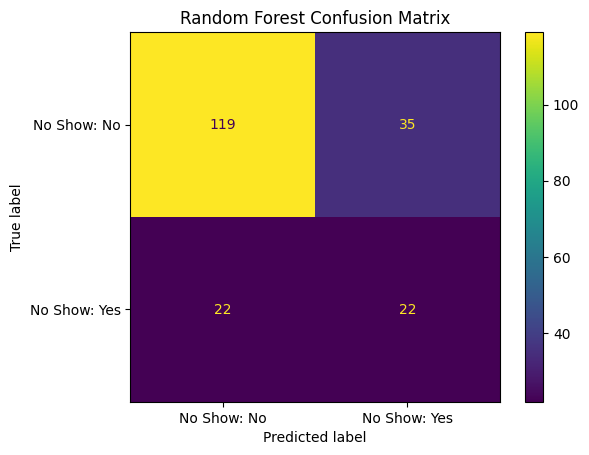

In [23]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

rf_cm = confusion_matrix(y_test, rf_predictions)

print("Random Forest Confusion Matrix:")
print(rf_cm)

ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Show: No", "No Show: Yes"]
).plot(cmap="viridis")

plt.title("Random Forest Confusion Matrix")
plt.show()


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
3,lead_days,0.244287
4,prior_no_shows,0.212324
2,fee_inr,0.143103
1,distance_km,0.125777
0,age,0.104093
5,reminder_sent,0.081391
7,booking_channel_Phone,0.026531
9,visit_type_Consultation,0.023687
10,visit_type_Follow-up,0.017247
6,booking_channel_App,0.011711


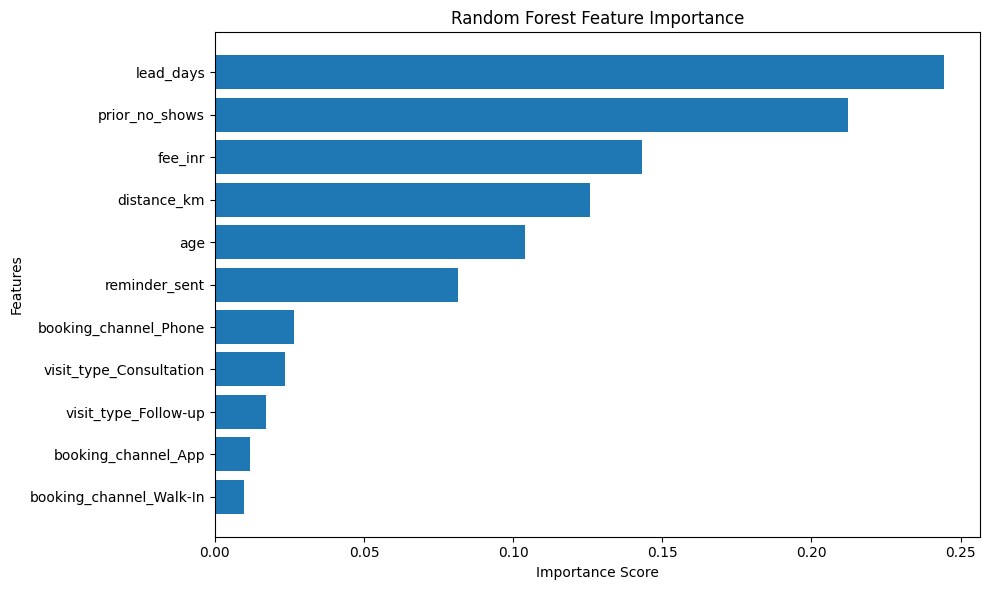

In [24]:

# Random Forest Feature Importance

rf_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(rf_feature_importance)

# Visualization

plt.figure(figsize=(10, 6))

plt.barh(
    rf_feature_importance["Feature"],
    rf_feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
3,lead_days,0.244287
4,prior_no_shows,0.212324
2,fee_inr,0.143103
1,distance_km,0.125777
0,age,0.104093
5,reminder_sent,0.081391
7,booking_channel_Phone,0.026531
9,visit_type_Consultation,0.023687
10,visit_type_Follow-up,0.017247
6,booking_channel_App,0.011711


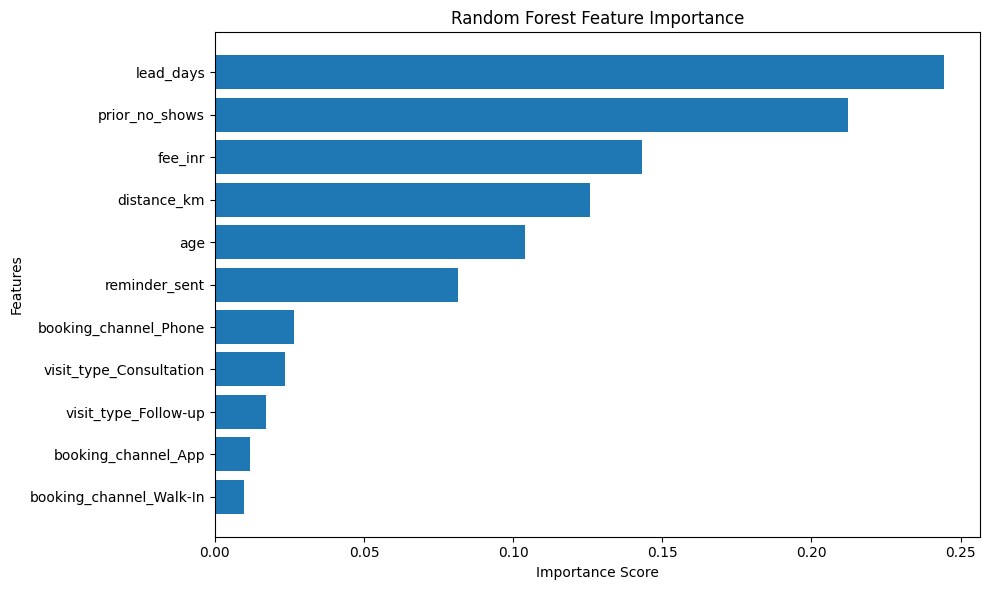

In [25]:

# Random Forest Feature Importance

rf_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(rf_feature_importance)

# Visualization

plt.figure(figsize=(10, 6))

plt.barh(
    rf_feature_importance["Feature"],
    rf_feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Task 3.5: Model Performance Comparison**

In [26]:

# Model Performance Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Full Decision Tree",
        "Depth 3 Decision Tree",
        "Random Forest"
    ],
    "Testing Accuracy": [
        0.7929,
        full_test_accuracy,
        depth3_test_accuracy,
        rf_accuracy
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(model_comparison)


MODEL PERFORMANCE COMPARISON


,Model,Testing Accuracy
0,Logistic Regression,0.792900
1,Full Decision Tree,0.737374
2,Depth 3 Decision Tree,0.797980
3,Random Forest,0.712121


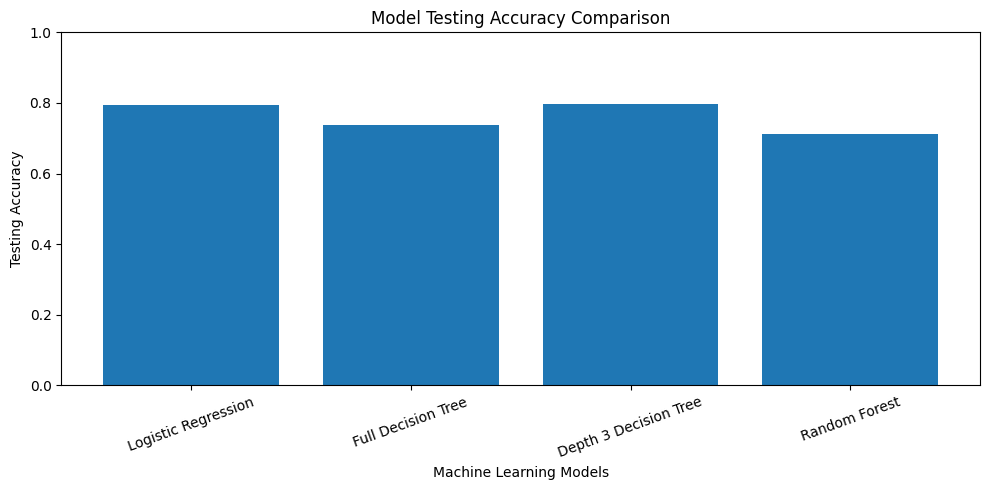

In [27]:

plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Testing Accuracy"]
)

plt.title("Model Testing Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Testing Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [28]:

best_model_index = model_comparison[
    "Testing Accuracy"
].idxmax()

best_model = model_comparison.loc[
    best_model_index
]

print("BEST PERFORMING MODEL")
print("---------------------")
print("Model:", best_model["Model"])
print(
    "Testing Accuracy:",
    round(best_model["Testing Accuracy"], 4)
)

print("\nBaseline Accuracy:", 0.7778)


BEST PERFORMING MODEL
---------------------
Model: Depth 3 Decision Tree
Testing Accuracy: 0.798

Baseline Accuracy: 0.7778


In [29]:
from sklearn.model_selection import GridSearchCV, cross_val_score, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

print("Task 3.5 Libraries Imported Successfully!")

Task 3.5 Libraries Imported Successfully!


In [30]:
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 8]
    },
    cv=5,
    scoring="roc_auc"
)

rf_grid.fit(X_train, y_train)

print("BEST RANDOM FOREST PARAMETERS")
print("------------------------------")
print("Best Parameters:", rf_grid.best_params_)
print("Best CV ROC-AUC:", round(rf_grid.best_score_, 4))

BEST RANDOM FOREST PARAMETERS
------------------------------
Best Parameters: {'max_depth': 5, 'n_estimators': 200}
Best CV ROC-AUC: 0.766


In [31]:
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

dt3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

rf_base = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

lr_cv = cross_val_score(
    lr_pipe, X_train, y_train,
    cv=5, scoring="roc_auc"
).mean()

dt_cv = cross_val_score(
    dt3, X_train, y_train,
    cv=5, scoring="roc_auc"
).mean()

rf_cv = cross_val_score(
    rf_base, X_train, y_train,
    cv=5, scoring="roc_auc"
).mean()

print("CROSS VALIDATION RESULTS")
print("------------------------")
print("Logistic Regression:", round(lr_cv, 4))
print("Depth 3 Decision Tree:", round(dt_cv, 4))
print("Random Forest:", round(rf_cv, 4))
print("Tuned Random Forest:", round(rf_grid.best_score_, 4))

CROSS VALIDATION RESULTS
------------------------
Logistic Regression: 0.7988
Depth 3 Decision Tree: 0.685
Random Forest: 0.7416
Tuned Random Forest: 0.766


In [32]:
best_model = lr_pipe

print("BEST MODEL SELECTED")
print("-------------------")
print("Model: Logistic Regression")
print("Cross-Validation ROC-AUC:", round(lr_cv, 4))

BEST MODEL SELECTED
-------------------
Model: Logistic Regression
Cross-Validation ROC-AUC: 0.7988


In [33]:
import numpy as np
import pandas as pd

oof_probabilities = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

print("Cross-Validation Probabilities Generated!")
print("Total Probabilities:", len(oof_probabilities))

Cross-Validation Probabilities Generated!
Total Probabilities: 792


In [34]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in [0.50, 0.35]:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions),
        "Recall": recall_score(y_train, predictions),
        "F1 Score": f1_score(y_train, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON")
display(threshold_df)

THRESHOLD COMPARISON


,Threshold,Precision,Recall,F1 Score
0,0.50,0.639535,0.316092,0.423077
1,0.35,0.559211,0.488506,0.521472


In [35]:
FINAL_THRESHOLD = 0.35

print("FINAL THRESHOLD SELECTED")
print("------------------------")
print("Selected Threshold:", FINAL_THRESHOLD)

FINAL THRESHOLD SELECTED
------------------------
Selected Threshold: 0.35


In [36]:
best_model.fit(X_train, y_train)

print("Final Logistic Regression Model Trained!")

# Generate test probabilities
test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
final_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

print("Test Predictions Generated:", len(final_predictions))

Final Logistic Regression Model Trained!
Test Predictions Generated: 198


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("FINAL MODEL TEST RESULTS")
print("=========================")

print("Accuracy:", round(
    accuracy_score(y_test, final_predictions), 4))

print("Precision:", round(
    precision_score(y_test, final_predictions), 4))

print("Recall:", round(
    recall_score(y_test, final_predictions), 4))

print("F1 Score:", round(
    f1_score(y_test, final_predictions), 4))

print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

FINAL MODEL TEST RESULTS
Accuracy: 0.7677
Precision: 0.4808
Recall: 0.5682
F1 Score: 0.5208
ROC-AUC: 0.7528

Confusion Matrix:
[[127  27]
 [ 19  25]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.82      0.85       154
           1       0.48      0.57      0.52        44

    accuracy                           0.77       198
   macro avg       0.68      0.70      0.68       198
weighted avg       0.78      0.77      0.77       198



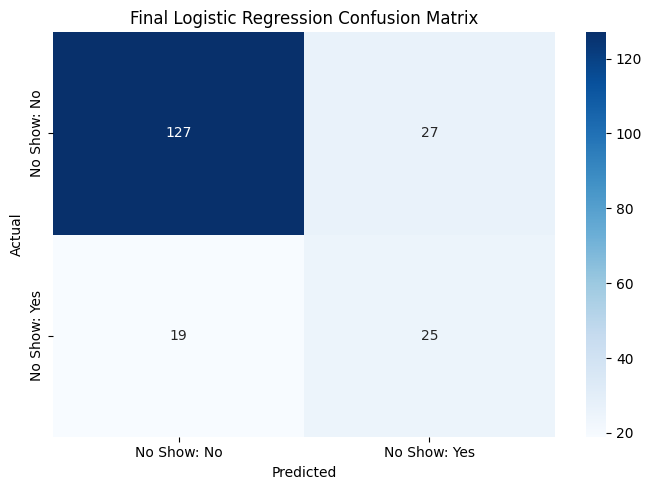

Final Confusion Matrix Generated Successfully!


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Show: No", "No Show: Yes"],
    yticklabels=["No Show: No", "No Show: Yes"]
)

plt.title("Final Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Final Confusion Matrix Generated Successfully!")

In [39]:
risk_scores = pd.DataFrame({
    "test_row_index": X_test.index,
    "actual_no_show": y_test.values,
    "no_show_probability": test_probabilities,
    "predicted_no_show": final_predictions
})

risk_scores["risk_category"] = np.where(
    risk_scores["no_show_probability"] >= FINAL_THRESHOLD,
    "High Risk",
    "Low Risk"
)

print("PATIENT RISK SCORES GENERATED")
print("--------------------------------")

display(risk_scores.head(10))

print("\nTotal Patients:", len(risk_scores))
print("\nRisk Distribution:")
print(risk_scores["risk_category"].value_counts())

PATIENT RISK SCORES GENERATED
--------------------------------


,test_row_index,actual_no_show,no_show_probability,predicted_no_show,risk_category
0,845,0,0.063279,0,Low Risk
1,931,0,0.098360,0,Low Risk
2,160,0,0.159873,0,Low Risk
3,654,0,0.046544,0,Low Risk
4,843,0,0.227083,0,Low Risk
5,644,0,0.055002,0,Low Risk
6,208,0,0.405061,1,High Risk
7,633,0,0.023827,0,Low Risk
8,350,0,0.133198,0,Low Risk
9,30,1,0.059694,0,Low Risk



Total Patients: 198

Risk Distribution:
risk_category
Low Risk     146
High Risk     52
Name: count, dtype: int64


In [40]:
output_file = "test_risk_scores.csv"

risk_scores.to_csv(output_file, index=False)

print("FINAL CSV EXPORTED SUCCESSFULLY!")
print("File Name:", output_file)

from google.colab import files
files.download(output_file)

FINAL CSV EXPORTED SUCCESSFULLY!
File Name: test_risk_scores.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import pandas as pd

check_df = pd.read_csv("appointments_clean.csv")

print("Dataset Shape:", check_df.shape)

print("\nNo-Show Distribution:")
print(check_df["no_show"].value_counts())

print("\nFirst 5 Appointment IDs:")
print(check_df["appointment_id"].head())

Dataset Shape: (990, 16)

No-Show Distribution:
no_show
0    772
1    218
Name: count, dtype: int64

First 5 Appointment IDs:
0    A0001
1    A0002
2    A0003
3    A0004
4    A0005
Name: appointment_id, dtype: object
